In [1]:
import hoomd
import gsd.hoomd
import matplotlib.pyplot as plt
import numpy as np
from hoomd.sqd_plugin import sqd_potential
# from hoomd.md import 

In [2]:
# from hoomd.azplugins import pair

In [68]:
nlist = hoomd.md.nlist.Cell(buffer=0.4, exclusions=('bond',))

In [69]:
# nlist

In [70]:
# ph = pair.Hertz(nlist)

In [71]:
sqd = sqd_potential.SquareDensity(nlist, default_r_cut=3.0)

In [72]:
a = 10.0
b = 10.0
c = 0.0

sqd.params[('A', 'B')] = dict(A=a, B=b, C=c)
sqd.params[('B', 'B')] = dict(A=a, B=b, C=c)
sqd.params[('A', 'A')] = dict(A=a, B=b, C=c)

In [73]:
snapshot = gsd.hoomd.Frame()

# Place a polymer in the box.
N = 50
snapshot.particles.N = N
snapshot.particles.position = np.random.randint(-10,10,size=(N,3))
snapshot.particles.types = ['A','B']
snapshot.particles.typeid = ([0] * (N//2)) + ([1] * (N//2))
snapshot.configuration.box = [20, 20, 20, 0, 0, 0]

# Connect particles with bonds.
snapshot.bonds.N = N-1
snapshot.bonds.types = ['A-A']
snapshot.bonds.typeid = [0] * (N-1)
snapshot.bonds.group = np.dstack((np.arange(0,N-1),np.arange(1,N)))

with gsd.hoomd.open(name='molecular.gsd', mode='w') as f:
    f.append(snapshot)

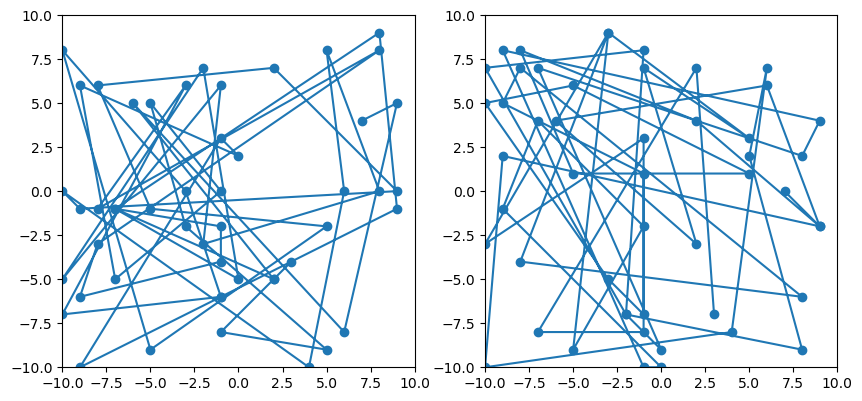

In [74]:
fig,ax = plt.subplots(1,2, figsize=(10,5))
ax[0].set(aspect=1, xlim=(-10,10),ylim=(-10,10))
ax[1].set(aspect=1, xlim=(-10,10),ylim=(-10,10))
ax[0].plot(snapshot.particles.position[:,0],snapshot.particles.position[:,1], marker="o")
ax[1].plot(snapshot.particles.position[:,0],snapshot.particles.position[:,2], marker="o")

In [75]:
# Apply the harmonic potential on the bonds.
harmonic = hoomd.md.bond.Harmonic()
harmonic.params['A-A'] = dict(k=100, r0=1.0)

# Perform the MD simulation.
sim = hoomd.Simulation(device=hoomd.device.CPU(), seed=1)
sim.create_state_from_gsd(filename='molecular.gsd')
langevin = hoomd.md.methods.Langevin(filter=hoomd.filter.All(), kT=1.0)

integrator = hoomd.md.Integrator(dt=0.005,
                                 methods=[langevin],
                                 forces=[sqd,harmonic])
gsd_writer = hoomd.write.GSD(filename='molecular_trajectory.gsd',
                             trigger=hoomd.trigger.Periodic(100),
                             mode='wb')
sim.operations.integrator = integrator
sim.operations.writers.append(gsd_writer)

In [76]:
sim.run(10000)
gsd_writer.flush()

In [77]:
traj = gsd.hoomd.open("molecular_trajectory.gsd", 'r')

In [78]:
len(traj)

100

In [79]:
# new_snap = traj[0]

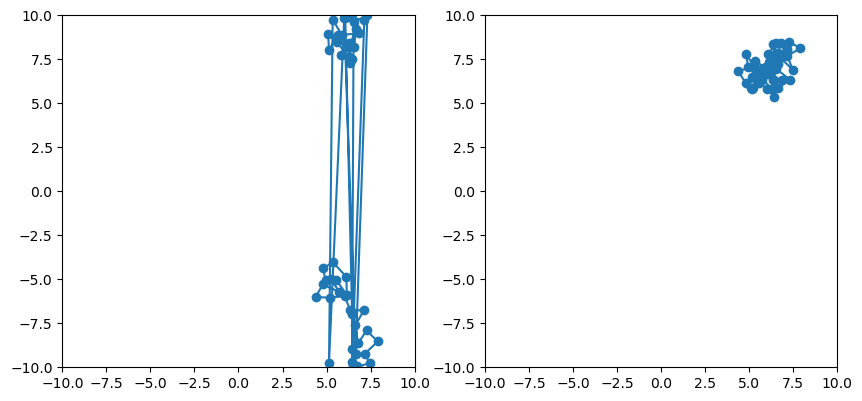

In [80]:
new_snap = traj[-1]
fig,ax = plt.subplots(1,2, figsize=(10,5))
ax[0].set(aspect=1, xlim=(-10,10),ylim=(-10,10))
ax[1].set(aspect=1, xlim=(-10,10),ylim=(-10,10))
ax[0].plot(new_snap.particles.position[:,0],new_snap.particles.position[:,1], marker="o")
ax[1].plot(new_snap.particles.position[:,0],new_snap.particles.position[:,2], marker="o")